## Dodgers Pitch Arsenal Classifier - Milestone 2: The Classifier

#### This notebook loads the cleaned pitch data from Milestone 1, trains a Random Forest classifier on physical pitch features, and evaluates it with a confusion matrix, accuracy, and a per-pitch classification report.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, classification_report

## 1. Load and Prepare Data

#### Load the cleaned data saved by 01_exploration (`data/pitches_clean.csv`): 5,384 pitches from Yamamoto, Glasnow, and Stone, with missing values and sweepers (ST) already removed.

#### The model only uses physical features. `effective_speed` is left out because it is almost identical to `release_speed` (correlation 0.99), so it adds nothing new.

In [2]:
results_filtered = pd.read_csv('data/pitches_clean.csv')
print("Rows:", len(results_filtered))
print(results_filtered['pitch_type'].value_counts())

Rows: 5384
pitch_type
FF    1959
SL     869
CU     775
SI     673
CH     574
FS     345
FC     189
Name: count, dtype: int64


In [3]:
physical_attributes = ['release_speed', 'release_pos_x', 'release_pos_y', 'release_pos_z', 'arm_angle', 'release_spin_rate', 'spin_axis', 'release_extension', 'pfx_x', 'pfx_z']
print("Physical Attributes:", physical_attributes)

Physical Attributes: ['release_speed', 'release_pos_x', 'release_pos_y', 'release_pos_z', 'arm_angle', 'release_spin_rate', 'spin_axis', 'release_extension', 'pfx_x', 'pfx_z']


## 2. Select Features and Target

#### `X` holds the 10 physical features, which describe what the ball does in flight. `Y` is the pitch type the model is trying to predict. No outcome columns (swing result, exit velocity, launch angle) are included. A hitter doesn't know the outcome before deciding to swing, so the model shouldn't either.

In [4]:
X = results_filtered[physical_attributes]
Y = results_filtered['pitch_type']
print (X.shape)
print(Y.value_counts())

(5384, 10)
pitch_type
FF    1959
SL     869
CU     775
SI     673
CH     574
FS     345
FC     189
Name: count, dtype: int64


## 3. Train/Test Split

#### Hold out 20% of the pitches for testing. The model never sees these during training, so the test score shows how well it handles new pitches instead of ones it has already memorized.

#### `stratify=Y` keeps each pitch type's share the same in both sets. This matters for cutters, which are only about 3.5% of the data. Without it, the test set could end up with too few cutters to judge.

In [5]:
X_train, X_test, Y_train, Y_test = train_test_split (X, Y, test_size=0.2, random_state=42, stratify=Y)
print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (4307, 10)
Test set size: (1077, 10)


## 4. Train Random Forest Classifier

#### A Random Forest builds many decision trees, each on a random sample of the data, and lets them vote on the answer. It fits this problem for three reasons:
#### - It handles features in different units (mph, rpm, degrees, feet) without needing to scale them.
#### - It can learn combined rules like "fast *and* rising = four-seam fastball."
#### - It reports which features it relied on most.

#### The tradeoff compared with a simpler model like a single decision tree or logistic regression is that it's harder to explain exactly why it made any one prediction.

In [6]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, Y_train)
print ("Model trained successfully.")

Model trained successfully.


## 5. Evaluate

#### The confusion matrix shows actual pitch type in the rows and predicted pitch type in the columns. Correct predictions fall on the diagonal. Below it: overall accuracy, precision and recall for each pitch, the list of misclassified pitches, and which features mattered most to the model.

In [7]:
y_pred = rf_model.predict(X_test)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = sorted(Y_test.unique())
cm = confusion_matrix(Y_test, y_pred, labels=labels)

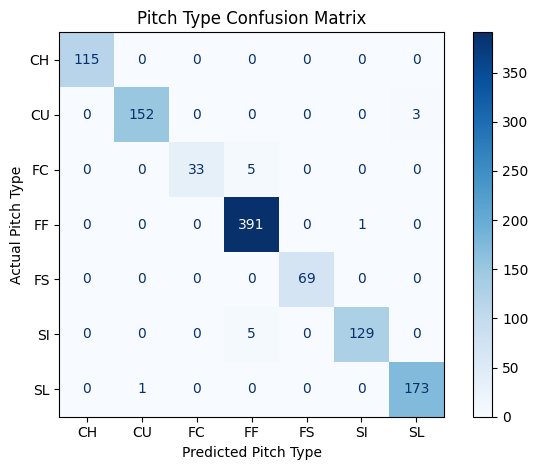

In [8]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues')
plt.title('Pitch Type Confusion Matrix')
plt.xlabel('Predicted Pitch Type')
plt.ylabel('Actual Pitch Type')
plt.tight_layout()
plt.show()

In [9]:
print("Accuracy:", round(accuracy_score(Y_test, y_pred), 4))
print()
print(classification_report(Y_test, y_pred))

# Which pitches got mixed up, and how often
misses = pd.DataFrame({'actual': Y_test.values, 'predicted': y_pred})
misses = misses[misses['actual'] != misses['predicted']]
print("Misclassified pitches:", len(misses))
print(misses.value_counts())

# Which features the model relied on most
importances = pd.Series(rf_model.feature_importances_, index=physical_attributes).sort_values(ascending=False)
print()
print(importances.round(3))


Accuracy: 0.9861

              precision    recall  f1-score   support

          CH       1.00      1.00      1.00       115
          CU       0.99      0.98      0.99       155
          FC       1.00      0.87      0.93        38
          FF       0.98      1.00      0.99       392
          FS       1.00      1.00      1.00        69
          SI       0.99      0.96      0.98       134
          SL       0.98      0.99      0.99       174

    accuracy                           0.99      1077
   macro avg       0.99      0.97      0.98      1077
weighted avg       0.99      0.99      0.99      1077

Misclassified pitches: 15
actual  predicted
SI      FF           5
FC      FF           5
CU      SL           3
FF      SI           1
SL      CU           1
Name: count, dtype: int64

release_speed        0.246
pfx_z                0.207
pfx_x                0.180
spin_axis            0.135
release_spin_rate    0.106
release_pos_x        0.065
arm_angle            0.018
release_po

## Checkpoint: Which pitches does the model confuse?

#### The model labeled **98.6%** of test pitches correctly (1,062 of 1,077). The 15 misses fall into two groups:

| Actual pitch | Predicted as | Misses |
|---|---|---|
| Sinker (SI) | Four-Seam (FF) | 5 |
| Cutter (FC) | Four-Seam (FF) | 5 |
| Curveball (CU) | Slider (SL) | 3 |
| Four-Seam (FF) | Sinker (SI) | 1 |
| Slider (SL) | Curveball (CU) | 1 |

#### **Fastballs (11 of 15 misses).** Sinkers and cutters were most often called four-seamers. All three are thrown hard. They differ mainly in a few inches of late movement: a sinker runs and drops, and a cutter breaks slightly glove-side. A sinker or cutter that doesn't move much looks like a four-seamer. The cutter was the hardest pitch for the model: it caught only 87% of them (33 of 38). It is also the rarest pitch in the data, so the model had the fewest examples to learn from.

#### **Breaking balls (4 of 15 misses).** Curveballs and sliders both spin hard and break away from the pitcher's arm side. A tight, hard curveball can look a lot like a slider.

#### **Does the model fail where hitters do?** Mostly, yes. These are the same pairings pitchers use to fool hitters: a sinker or cutter that looks like a fastball until it moves late, or a slider and curveball thrown from the same arm slot. The model never confused the changeup or splitter with anything, because they are much slower than the fastballs.

#### **Most important features:** release speed (24.6%), vertical movement `pfx_z` (20.7%), and horizontal movement `pfx_x` (18.0%). These are the same features that separated the pitch types in the 01_exploration plots.

#### **Reading the 98.6% carefully.** The real-world score would probably be lower, for two reasons:
#### - There are only three pitchers, and release position and arm angle can tell the model who is pitching.
#### - Statcast's pitch labels come from MLB's own classifier, which uses similar measurements.

#### A tougher test would be to train on two pitchers and test on the third.